# racetraQ 08 — Does it drive tracks it never saw?

Every driver in this repository is judged by laps: 72 of 72 fresh episodes,
36 of 36 in the reliability eval. But a driver that laps its training track
72 times out of 72 has passed an exam it studied for. Machine learning has
two standard questions for any result like that, and this notebook asks both
of them, with the bundled drivers and the committed study data — no training.

- **Part A — tracks it never saw.** What a *training set* and a *test set*
  are when the data is a race track; what **overfitting** looks like for a
  driver; and an experiment: four quantum drivers and two classical ones on
  eight freshly generated tracks that none of them was trained or selected
  on.
- **Part B — episodes it was picked on.** The best snapshot of a training
  run is chosen by its in-training eval. How optimistic does that make the
  eval? All 645 comparable training runs of `data/studies/` answer it, with a
  control group, and the answer explains why every bundled driver is
  re-evaluated on fresh episodes before it ships.

Both parts are the same idea: **a number measured on what you fitted, or on
what you picked with, is optimistic.** Only data you never touched says how
good a model is.

You need [notebook 04](04_training_the_quantum_driver.ipynb), Parts A and D:
the snapshot eval log, the best snapshot, the 36-episode reliability eval,
and the `.meta.json` sidecar of a bundled driver. The notebook runs in about
a minute.

In [1]:
# On Binder (QuBins images) this repo arrives via nbgitpuller without being
# pip-installed; install it from GitHub only if the import fails.
try:
    import racetraq  # noqa: F401
except ImportError:
    %pip install -q git+https://github.com/JanLahmann/racetraQ

import json
import time
import urllib.request
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np

from racetraq import records
from racetraq.agents.base import action_labels
from racetraq.agents.classical import MLPQFunction
from racetraq.agents.quantum import QuantumQFunction
from racetraq.env.racing_env import RacingEnv
from racetraq.env.track import Track
from racetraq.env.trackgen import generate_track

# one colour per kind of model, as in notebook 04; pass / fail marks for the track grid
C_QUANTUM, C_MLP, C_NEUTRAL = "#2a78d6", "#eb6834", "#8a8a86"
T_START = time.perf_counter()
HEAD = {}  # headline numbers collected along the way for the summary at the end

REPO = next((base for base in [Path.cwd(), *Path.cwd().parents]
             if (base / "data" / "studies").is_dir()), None)
RAW = "https://raw.githubusercontent.com/JanLahmann/racetraQ/main/data"
print("committed data:", "data/ of this checkout" if REPO else f"{RAW} (no checkout found)")
_loaded = {}


def repo_json(relpath):
    """data/<relpath>: from the checkout, else from the repository on GitHub."""
    if relpath not in _loaded:
        if REPO is not None:
            text = (REPO / "data" / relpath).read_text(encoding="utf-8")
        else:
            try:
                with urllib.request.urlopen(f"{RAW}/{relpath}") as response:
                    text = response.read().decode("utf-8")
            except OSError as exc:  # no network
                raise FileNotFoundError(
                    f"data/{relpath}: not next to this notebook and not fetchable from {RAW}; "
                    "run the notebook from a clone of the repository") from exc
        _loaded[relpath] = json.loads(text)
    return _loaded[relpath]

committed data: data/ of this checkout


## Part A — Tracks it never saw

### Training set and test set

In supervised learning the rule is simple: keep some of the data back, fit
the model on the rest, and report its error on the part it never saw — the
**test set**. A model that is excellent on its training data and poor on the
test set has **overfitted**: it learned the particular examples instead of
the pattern behind them. **Generalisation** is the opposite — doing well on
new data of the kind it was trained for.

Reinforcement learning has no fixed dataset, but the same split exists. The
agent trains on some *environments* — here, race tracks — and the honest
question is how it drives on tracks that were never part of training. An
overfitted driver is one that learned *its track* rather than *driving*:
sensor-to-action rules that happen to work in the corners it has seen and
fail in others.

Nothing in the driver's input ties it to one track. It sees no map and no
position, only three distance rays and its speed (the cell prints them), so
the same rules *can* be applied anywhere. Whether they *work* anywhere
depends on which situations training showed it. The six bundled drivers this
part uses:

In [2]:
DRIVERS = ("quantum_oval", "quantum_chicane", "quantum_gp", "quantum_universal",
           "mlp_oval", "mlp_gp")
BUNDLED = ("oval", "chicane", "gp", "combo")
bundled = {d.id: d for d in records.discover_drivers()}


def sidecar(name):
    """The .meta.json next to a bundled weights file."""
    return json.loads((records.WEIGHTS_DIR / f"{name}.meta.json").read_text(encoding="utf-8"))


def trained_on(name):
    """The bundled tracks a driver was trained on ("multi" = all four, round-robin)."""
    track = sidecar(name)["track"]
    return BUNDLED if track == "multi" else (track,)


def load_driver(name):
    """(config, Q-function with the bundled weights) of a bundled driver."""
    driver = bundled[name]
    params = np.load(driver.path)["params"]
    if driver.kind == "quantum":
        qfunc = QuantumQFunction(driver.config["circuit"])
    else:  # the bundled MLPs: 4 inputs, one hidden layer, 4 actions
        hidden = (params.size - 4) // (4 + 1 + 4)
        qfunc = MLPQFunction(n_features=4, hidden=hidden, n_actions=4)
    qfunc.set_params(params)
    return driver.config, qfunc


def color(name):
    return C_QUANTUM if name.startswith("quantum") else C_MLP


print(f"{'driver':<19}{'parameters':>11}{'training episodes':>19}   trained on")
for name in DRIVERS:
    meta = sidecar(name)
    _, qfunc = load_driver(name)
    print(f"{name:<19}{qfunc.n_params:>11}{meta['episodes']:>19}   {', '.join(trained_on(name))}")
features = RacingEnv(Track.load("oval"), bundled["quantum_oval"].config, n_envs=1,
                     seed=0).feature_names
print(f"\nwhat every one of them sees, ten times a second: {', '.join(features)}")

driver              parameters  training episodes   trained on
quantum_oval                56                800   oval
quantum_chicane             56                800   chicane
quantum_gp                  56               3000   gp
quantum_universal           56               3000   oval, chicane, gp, combo
mlp_oval                    76                800   oval
mlp_gp                      76               3000   gp

what every one of them sees, ten times a second: ray -60°, ray 0°, ray +60°, speed


`quantum_universal` is one 4-qubit circuit trained on all four bundled tracks
in turn (round-robin over parallel cars); the others are **specialists**,
trained on one track each. The two MLPs are the classical baselines of
notebook 04, for comparison.

### First test: the other bundled tracks

For a specialist, the three bundled tracks it was not trained on are a test
set. `data/records.json` holds every bundled driver on every bundled track:
36 standing-start greedy episodes per cell, from an env seed that no driver
selection used.

In [3]:
rec = repo_json("records.json")["records"]
print("episodes that lapped, of 36 standing starts, and the mean lap (env seed 47000, "
      "data/records.json);\n* = a track the driver was trained on\n")
print(f"{'driver':<19}" + "".join(f"{t:>14}" for t in BUNDLED)
      + "   lapped off its training tracks")
HEAD["transfer"] = {}
for name in DRIVERS:
    row, off = "", []
    for t in BUNDLED:
        r = rec[f"{name}|{t}"]
        assert r["episodes"] == 36
        home = t in trained_on(name)
        lap = f"{r['mean_s']:.1f} s" if r["mean_s"] is not None else "—"
        row += f"{r['lapped_episodes']:>5}{'*' if home else ' '}{lap:>8}"
        if not home:
            off.append(r["lapped_episodes"])
    HEAD["transfer"][name] = (sum(off), 36 * len(off))
    print(f"{name:<19}{row}   "
          + (f"{sum(off)} of {36 * len(off)}" if off else "— (no such track)"))

episodes that lapped, of 36 standing starts, and the mean lap (env seed 47000, data/records.json);
* = a track the driver was trained on

driver                       oval       chicane            gp         combo   lapped off its training tracks
quantum_oval          36*  12.7 s    2   13.5 s    0        —    0        —   2 of 108
quantum_chicane       35   12.6 s   35*  12.7 s    0        —    0        —   35 of 108
quantum_gp            36   22.2 s   36   22.8 s   36*  27.9 s   21   32.9 s   93 of 108
quantum_universal     36*  27.6 s   36*  27.4 s   36*  35.2 s   36*  38.2 s   — (no such track)
mlp_oval              36*  12.6 s   36   12.7 s    0        —    0        —   36 of 108
mlp_gp                36   17.3 s   36   17.9 s   36*  22.5 s    1   27.5 s   73 of 108


Read the table by rows. The oval specialists lap the oval and fail on gp and
combo; `quantum_oval` does not even transfer to the chicane (2 of 36), while
`mlp_oval` does (36 of 36). The gp specialists lap the oval and the chicane
as well — a driver that has learned to brake for gp's hairpin also gets
round the flat-out tracks, while the reverse never happens: transfer runs
downhill, from the hard track to the easy ones.

The universal driver's row has a problem: every bundled track is one of its
training tracks. Its 36 of 36 everywhere is a *training* score. To test it,
we need tracks that nobody trained on.

### Tracks from a generator

`racetraq.env.trackgen.generate_track(seed, difficulty=...)` builds a random
closed track, the same one for the same seed: a wobbly loop with two
guaranteed hairpins and an S-chicane, stretched into a random oval-ish shape.
`difficulty` (0 to 1) makes it narrower and its tightest corner tighter;
0.65 is what the demo's random-track button uses.

Which seeds? Not 100–109: `tools/bundle_driver.py` drove the universal
candidates on exactly those tracks when it *chose* which seed to ship (the
sidecar records it; the next cell prints it). A track that was used to pick
the model is no longer a test track for it — Part B measures what such a
choice does to the numbers. The technical report's re-checks also used
300–309 and 500–509. This notebook takes 800–807.

In [4]:
TEST_SEEDS = tuple(range(800, 808))  # trackgen seeds no driver was trained or selected on
DIFFICULTY = 0.65                    # the demo's random-track difficulty
SPACING = bundled["quantum_universal"].config["track"]["resample_spacing"]

used = sidecar("quantum_universal")["selection"]["unseen_eval"]
print(f"quantum_universal was SELECTED on trackgen seeds {used['trackgen_seeds'][0]}-"
      f"{used['trackgen_seeds'][1]} (difficulty {used['difficulty']}, "
      f"{used['episodes_per_track']} episodes each) -> those are no test set for it")

tests = [generate_track(seed, SPACING, difficulty=DIFFICULTY) for seed in TEST_SEEDS]


def tightest(track):
    """Radius of the tightest corner (1 / largest curvature)."""
    return 1.0 / track.max_abs_curvature


print(f"\n{'track':<12}{'length':>8}{'width':>7}{'tightest corner (radius)':>26}")
for t in [Track.load(name, SPACING) for name in BUNDLED] + tests:
    print(f"{t.name:<12}{t.total_length:>8.0f}{2 * t.half_width:>7.1f}{tightest(t):>26.1f}")

quantum_universal was SELECTED on trackgen seeds 100-109 (difficulty 0.65, 12 episodes each) -> those are no test set for it

track         length  width  tightest corner (radius)
oval             337   14.0                      24.5
chicane          343   14.0                       9.9
gp               429   12.0                       9.0
combo            492   12.0                       8.6
random-800       584    9.4                       8.6
random-801       583    9.4                       7.7
random-802       629    9.4                       8.2
random-803       520    9.4                       8.6
random-804       544    9.4                       8.6
random-805       423    9.4                       8.6
random-806       640    9.4                       7.9
random-807       571    9.4                       8.6


Compared with the bundled tracks, the generated ones are mostly longer,
narrower (9.4 units wide against 12 to 14), and their tightest corners are
at least as tight as gp's. So "never seen" also means "a bit harder than anything in
training": the test tracks do not come from the training distribution. That
is the realistic case — a driver handed a drawn or random track in the demo
faces exactly that — and it is a harder test than a held-out track of the
same kind would be.

### Experiment A: six drivers, eight new tracks

The cell drives every driver on every generated track: 12 greedy episodes
per track, each a standing start with its own small random offset, ending at
the first crash or after the 60-second budget — the same evaluation as
notebook 04's reliability eval, with an env seed of its own. It also records
where each car left the track and how often each driver chose *Brake*.

In [5]:
EPISODES, ENV_SEED = 12, 52_000  # 12 standing starts per track; an env seed no evaluation used


def drive(name, track, episodes=EPISODES, seed=ENV_SEED):
    """Greedy evaluation: `episodes` cars, one episode each (to the first crash or the 60 s
    budget). Returns episodes lapped, mean lap time, where cars left the track, and the share
    of decisions that were Brake."""
    config, qfunc = load_driver(name)
    env = RacingEnv(track, config, n_envs=episodes, seed=seed)
    brake = action_labels(env.n_actions).index("Brake")
    obs = env.reset()
    finished = np.zeros(episodes, dtype=bool)  # this car's one episode is over
    lapped = np.zeros(episodes, dtype=bool)
    prev_lap = np.zeros(episodes, dtype=int)
    lap_times, crash_points = [], []
    n_brake = n_decisions = 0
    for _ in range(env.max_decisions + 1):
        actions = np.argmax(qfunc.q_values(obs), axis=1)
        n_brake += int(np.sum((actions == brake) & ~finished))
        n_decisions += int(np.sum(~finished))
        before = env.state[:, :2].copy()  # positions at the start of this decision
        obs, _, done, info = env.step(actions)
        event = (info["lap"] > prev_lap) & ~finished  # a lap was completed in this step
        lap_times.extend(info["last_lap_time"][event])
        lapped |= event
        crash_points.extend(before[done & info["off_track"] & ~finished])
        finished |= done
        prev_lap = np.where(done, 0, info["lap"])  # a finished car respawns at lap 0
        if finished.all():
            break
    return {"lapped": int(lapped.sum()), "episodes": episodes,
            "mean_lap": float(np.mean(lap_times)) if lap_times else None,
            "crashes": np.array(crash_points).reshape(-1, 2), "brake": n_brake / n_decisions}


t0 = time.perf_counter()
results = {name: [drive(name, t) for t in tests] for name in DRIVERS}
print(f"episodes that lapped, of {EPISODES} per generated track (difficulty {DIFFICULTY}, "
      f"env seed {ENV_SEED})\n")
print(f"{'driver':<19}" + "".join(f"{s:>5}" for s in TEST_SEEDS)
      + f"{'total':>10}{'mean lap':>10}{'brake':>8}")
HEAD["unseen"] = {}
for name, rows in results.items():
    total = sum(r["lapped"] for r in rows)
    laps = [r["mean_lap"] for r in rows if r["mean_lap"] is not None]
    HEAD["unseen"][name] = (total, EPISODES * len(rows))
    print(f"{name:<19}" + "".join(f"{r['lapped']:>5}" for r in rows)
          + f"{total:>6}/{EPISODES * len(rows):<3}"
          + (f"{np.mean(laps):>9.1f}s" if laps else f"{'—':>10}")
          + f"{np.mean([r['brake'] for r in rows]):>8.0%}")
print("\nmean lap: over the tracks with at least one lap; brake: share of all decisions")
print(f"({len(DRIVERS) * len(tests) * EPISODES} episodes in {time.perf_counter() - t0:.0f} s)")

episodes that lapped, of 12 per generated track (difficulty 0.65, env seed 52000)

driver               800  801  802  803  804  805  806  807     total  mean lap   brake
quantum_oval           0    0    0    0    0    0    0    0     0/96          —     11%
quantum_chicane        0    0    1    0    0    0    0    0     1/96      26.2s      2%
quantum_gp            12   12   12   12   12   12   12   12    96/96      36.7s     19%
quantum_universal     12   12   12   12   12   12   12   12    96/96      47.7s     24%
mlp_oval               0    0    0    0    0    0    0    0     0/96          —      0%
mlp_gp                12   12   12   12   12   12   11   12    95/96      30.1s     14%

mean lap: over the tracks with at least one lap; brake: share of all decisions
(576 episodes in 22 s)


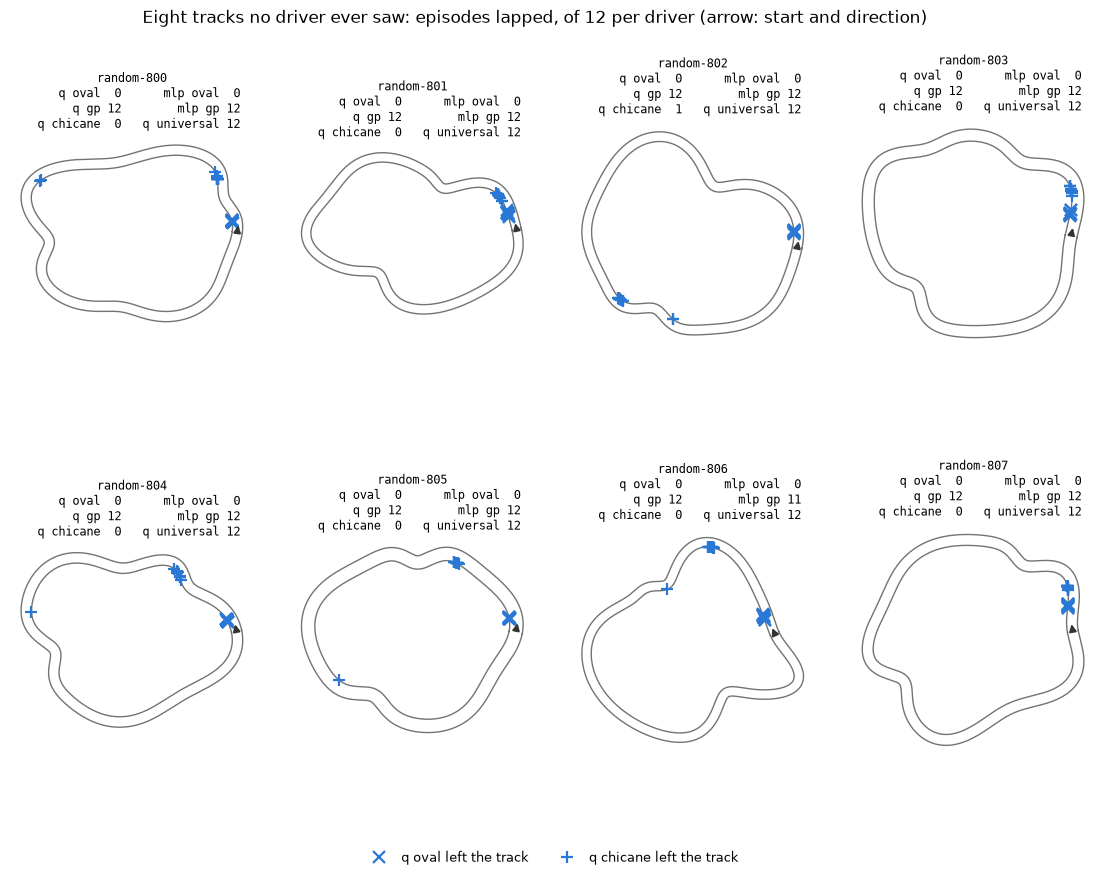

In [6]:
def draw_track(ax, track):
    cl, hw = track.centerline, track.half_width
    for sign in (+1.0, -1.0):
        edge = cl + sign * hw * track.normals
        edge = np.vstack([edge, edge[:1]])  # close the loop
        ax.plot(edge[:, 0], edge[:, 1], color="0.45", lw=1.0)
    x0, y0, h0 = track.start_pose()
    ax.annotate("", xy=(x0 + 9 * np.cos(h0), y0 + 9 * np.sin(h0)), xytext=(x0, y0),
                arrowprops=dict(arrowstyle="-|>", color="0.2", lw=1.5))
    ax.set_aspect("equal")
    ax.set_xticks([])
    ax.set_yticks([])
    for spine in ax.spines.values():
        spine.set_visible(False)


SHORT = {"quantum_oval": "q oval", "quantum_chicane": "q chicane", "quantum_gp": "q gp",
         "quantum_universal": "q universal", "mlp_oval": "mlp oval", "mlp_gp": "mlp gp"}
TITLE_ROWS = (("quantum_oval", "mlp_oval"), ("quantum_gp", "mlp_gp"),
              ("quantum_chicane", "quantum_universal"))
fig, axes = plt.subplots(2, 4, figsize=(14, 8.8), gridspec_kw={"hspace": 0.5, "wspace": 0.15})
for i, (ax, track) in enumerate(zip(axes.flat, tests, strict=True)):
    draw_track(ax, track)
    for name, marker in (("quantum_oval", "x"), ("quantum_chicane", "+")):
        pts = results[name][i]["crashes"]
        if pts.size:
            ax.plot(pts[:, 0], pts[:, 1], marker, color=C_QUANTUM, ms=8, mew=1.6, ls="none",
                    label=f"{SHORT[name]} left the track" if i == 0 else None)
    lines = ["   ".join(f"{SHORT[name]:>11} {results[name][i]['lapped']:>2}" for name in pair)
             for pair in TITLE_ROWS]
    ax.set_title(f"{track.name}\n" + "\n".join(lines), fontsize=8.5, family="monospace")
fig.legend(loc="lower center", ncol=2, frameon=False, fontsize=9)
fig.suptitle(f"Eight tracks no driver ever saw: episodes lapped, of {EPISODES} per driver "
             "(arrow: start and direction)", y=0.98)
plt.show()

The outcome is all or nothing, and the line between the two groups is not
quantum against classical:

- **The oval and chicane specialists fail.** `quantum_oval` and `mlp_oval`
  lap in none of their 96 episodes, `quantum_chicane` in one. In the figure,
  the crosses of `quantum_oval` sit at the first bend after the start on
  every track: it does not get one corner into an unfamiliar lap. It does
  press *Brake* (11 % of its decisions), but not in a way that keeps it on
  these tracks; `mlp_oval` never brakes on them at all.
- **The drivers trained where braking matters generalise.** `quantum_gp`
  laps 96 of 96, `mlp_gp` 95 of 96, and `quantum_universal` 96 of 96. They
  brake in 14 % to 24 % of their decisions.

So the specialist/universal split is not the whole story either: the gp
specialists, trained on one track, drive every new track. What decides is
whether training contained the *situation* the test needs — a corner that
cannot be taken flat out. The oval never asks for that, so an oval driver
never learns it, however perfect it is on the oval. That is overfitting in
the RL sense: not memorised data points, but a policy fitted to the narrow
range of situations one environment happens to produce.

The universal driver is slower than the gp specialists on the new tracks
(the mean-lap column), and on the bundled tracks too, as the records table
shows: one policy for every track drives all of them more slowly.

### Overfitting among the seeds of one recipe

The universal driver could have overfitted too. Its study trained the same
recipe on all four tracks from 5 seeds, and the seed that tops the study's
ranking on the training tracks is *not* the one that ships. From the
sidecar of `quantum_universal`, every candidate's numbers: the study's
36-episode eval and 72 fresh episodes per track on the four training tracks,
and 120 episodes on the ten generated tracks of seeds 100–109:

In [7]:
sel = sidecar("quantum_universal")["selection"]
top = sel["candidates"][0]  # candidates are listed in the study's ranking order
print(f"quantum_universal: {sel['n_seeds']} training seeds of the same recipe, "
      f"ranked by the study's eval on the training tracks\n")
print(f"{'seed':>5}{'study eval':>13}{'fresh, training tracks':>25}{'mean lap':>10}"
      f"{'generated tracks':>18}")
print(f"{'':>5}{'(36 episodes)':>13}{'(72 per track)':>25}{'':>10}"
      f"{'(seeds 100-109)':>18}")
for c in sel["candidates"]:
    mark = "   <- ranked first on the training tracks" if c is top else ""
    mark += "   <- bundled" if c["seed"] == sel["chosen_seed"] else ""
    print(f"{c['seed']:>5}{c['study_lapped']:>9}/{c['study_episodes']:<3}"
          f"{c['fresh_lapped']:>19}/{c['fresh_episodes']:<5}{c['fresh_mean_lap']:>8.1f} s"
          f"{c['unseen_lapped']:>12}/{c['unseen_episodes']}{mark}")
HEAD["universal_seeds"] = {c["seed"]: c for c in sel["candidates"]}

quantum_universal: 5 training seeds of the same recipe, ranked by the study's eval on the training tracks

 seed   study eval   fresh, training tracks  mean lap  generated tracks
     (36 episodes)           (72 per track)             (seeds 100-109)
    0       36/36                 283/288      18.3 s           0/120   <- ranked first on the training tracks
    3       36/36                 287/288      30.6 s         120/120   <- bundled
    1       34/36                 275/288      25.3 s          42/120
    2       26/36                 187/288      18.6 s           0/120
    4       24/36                 174/288      25.3 s          39/120


This table is overfitting in its textbook form. Seed 0 ranks first on its
training tracks — 36 of 36 in the study's eval, 283 of 288 fresh episodes,
and the fastest (18.3 s mean lap against seed 3's 30.6 s). On the generated
tracks it laps in **0 of 120** episodes. Seed 3 is at least as reliable on
the training tracks (287 of 288), slower there, and laps all 120 episodes on
the generated tracks. Better on the training set, useless on the test
set: training scores did not rank the seeds' generalisation at all.

A selection rule that only looks at the training tracks would have shipped
seed 0, and the demo's random-track and drawn-track modes, which hand the
car to `quantum_universal`, would have had a driver that cannot drive them.
Since October 2026 `tools/bundle_driver.py --unseen 10` ranks candidates on
generated tracks as well. Which is why Experiment A used new seeds: tracks
100–109 picked this driver, so they can no longer tell us how good it is.
Part B is about exactly that effect.

## Part B — Episodes it was picked on

### The in-training eval is a selection

Recall notebook 04: every 50 training episodes, the trainer lets the current
parameters drive 12 greedy episodes, from the same 12 start positions each
time. Whatever eval scores best (episodes lapped, then mean lap) becomes the
**best snapshot**, and that is what a weights file holds. A run of 800
episodes has 16 such evals, a gp run of 3000 has 60.

Each eval is a noisy measurement: 12 episodes is a small sample. Pick the
largest of 16 or 60 noisy measurements and you pick, in part, the one that
was *luckiest*. Its score therefore overstates how good the kept snapshot
is. This is **selection bias**, also called the *winner's curse*: the
winner of a noisy contest is, on average, worse than its winning score.

Every run in `data/studies/*/cells.json` records two numbers for its best
snapshot:

- `best_eval` — the in-training eval it was **picked on** (12 episodes);
- `best_snapshot_eval` — the reliability eval on **36 fresh episodes** from
  other start positions, which played no part in the choice.

The difference between them is the selection effect — if the two evals are
otherwise alike. To check that, the runs also give a **control group**: the
*last* in-training eval of every run (`final_eval`, the parameters at the
end of training, kept whatever they score) against the same 36-episode eval
of those final parameters (`final_params_eval`). Nobody picked those; if the
fresh episodes were simply harder than the in-training ones, the control
would show a gap too.

Left out: runs whose in-training evals drove under emulated device noise
(`act_noise`, the robust recipes of notebooks 04 and 05) — their two evals
differ in more than their episodes, so the comparison would not be fair.

In [8]:
STUDIES = ("chicane_4q", "chicane_q10", "chicane_q6", "chicane_q8", "combo_4q", "gp_4q",
           "gp_4q_followups", "gp_4q_pace30", "gp_q10feat", "gp_q10feat_8seeds",
           "gp_q10feat_pace_L4", "gp_q10feat_pace_L6", "gp_q10feat_plain", "gp_q10feat_widen",
           "levers_chicane_4q", "levers_gp_4q", "levers_oval_4q", "oval_4q", "oval_q10",
           "oval_q6", "oval_q8", "pro", "robust_chicane_4q", "robust_oval_4q", "robust_oval_q6",
           "universal_4q")  # the studies with a cells.json when this notebook was written
if REPO is not None:  # a checkout: every study it has
    STUDIES = tuple(sorted(p.parent.name for p in (REPO / "data" / "studies").glob("*/cells.json")))

runs, noisy = [], 0
for study in STUDIES:
    for cell in repo_json(f"studies/{study}/cells.json"):
        if "training.act_noise" in (cell.get("overrides") or {}):
            noisy += 1  # its in-training evals acted under emulated device noise: not comparable
            continue
        picked, fresh = cell["best_eval"], cell["best_snapshot_eval"]
        last, last_fresh = cell["final_eval"], cell["final_params_eval"]
        assert (picked["eval_episodes"], fresh["episodes"]) == (12, 36)
        assert last["episode"] == cell["eval_log"][-1]["episode"]  # the last eval, not picked
        runs.append({"study": study, "agent": cell["agent"], "track": cell["track"],
                     "n_evals": len(cell["eval_log"]),
                     "rank": (cell.get("overrides") or {}).get("training.snapshot_rank",
                                                                 "reliability"),
                     "picked": picked["lapped_episodes"] / 12,
                     "fresh": fresh["lapped_episodes"] / 36,
                     "last": last["lapped_episodes"] / last["eval_episodes"],
                     "last_fresh": last_fresh["lapped_episodes"] / 36,
                     "picked_lap": picked["mean_lap"], "fresh_lap": fresh["mean_lap"],
                     "fresh_best": fresh["best_lap"]})
print(f"{len(runs)} training runs from {len(STUDIES)} studies "
      f"({sum(r['agent'] == 'quantum' for r in runs)} circuit, "
      f"{sum(r['agent'] == 'mlp' for r in runs)} MLP); {noisy} runs left out (noisy acting)")
n_evals, n_runs = np.unique([r["n_evals"] for r in runs], return_counts=True)
print("snapshot evals per run (runs): "
      + ", ".join(f"{e} ({n})" for e, n in zip(n_evals, n_runs, strict=True)))

645 training runs from 26 studies (503 circuit, 142 MLP); 76 runs left out (noisy acting)
snapshot evals per run (runs): 12 (64), 16 (248), 30 (24), 50 (35), 60 (271), 100 (3)


In [9]:
def col(key):
    return np.array([r[key] for r in runs])


def mean_gap(a, b, n_boot=2000):
    """Mean of a - b over runs, with a 95 % percentile-bootstrap interval (runs resampled)."""
    d = a - b
    rng = np.random.default_rng(0)
    boot = d[rng.integers(0, d.size, size=(n_boot, d.size))].mean(axis=1)
    low, high = np.percentile(boot, [2.5, 97.5])
    return d.mean(), low, high


PAIRS = {"best snapshot (picked on its eval)": ("picked", "fresh"),
         "final params (not picked)": ("last", "last_fresh")}
print(f"{'':<36}{'in-training eval':>17}{'fresh 36':>10}{'gap [95 % interval]':>24}"
      f"{'eval higher / same / lower':>29}")
HEAD["gap"] = {}
for label, (a_key, b_key) in PAIRS.items():
    a, b = col(a_key), col(b_key)
    gap, low, high = mean_gap(a, b)
    HEAD["gap"][a_key] = (gap, low, high)
    print(f"{label:<36}{a.mean():>17.3f}{b.mean():>10.3f}"
          f"{f'{gap:+.3f} [{low:+.3f}, {high:+.3f}]':>24}"
          f"{f'{(a > b).sum()} / {(a == b).sum()} / {(a < b).sum()}':>29}")

print()
for label, (a_key, b_key) in PAIRS.items():
    a, b = col(a_key), col(b_key)
    perfect = a == 1
    HEAD.setdefault("perfect", {})[a_key] = (int((b[perfect] == 1).sum()), int(perfect.sum()),
                                             float(b[perfect].mean()))
    print(f"{label}: {perfect.sum()} runs lapped 12 of 12 in the in-training eval; "
          f"of those, {(b[perfect] == 1).sum()} lapped 36 of 36 fresh "
          f"(mean fresh fraction {b[perfect].mean():.3f})")

                                     in-training eval  fresh 36     gap [95 % interval]   eval higher / same / lower
best snapshot (picked on its eval)              0.765     0.737 +0.028 [+0.021, +0.036]               250 / 300 / 95
final params (not picked)                       0.337     0.332 +0.005 [-0.002, +0.011]              136 / 386 / 123

best snapshot (picked on its eval): 354 runs lapped 12 of 12 in the in-training eval; of those, 248 lapped 36 of 36 fresh (mean fresh fraction 0.974)
final params (not picked): 115 runs lapped 12 of 12 in the in-training eval; of those, 92 lapped 36 of 36 fresh (mean fresh fraction 0.981)


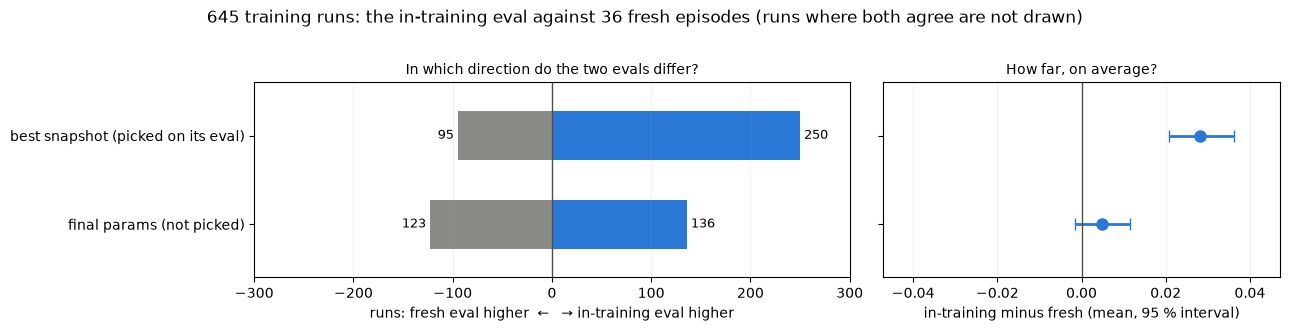

In [10]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 3.2), gridspec_kw={"width_ratios": [3, 2]})
rows = list(PAIRS.items())[::-1]  # best snapshot on top
for y, (_, (a_key, b_key)) in enumerate(rows):
    a, b = col(a_key), col(b_key)
    higher, lower = int((a > b).sum()), int((a < b).sum())
    ax1.barh(y, higher, height=0.55, color=C_QUANTUM)
    ax1.barh(y, -lower, height=0.55, color=C_NEUTRAL)
    ax1.text(higher + 4, y, str(higher), va="center", fontsize=9)
    ax1.text(-lower - 4, y, str(lower), va="center", ha="right", fontsize=9)
    gap, low, high = HEAD["gap"][a_key]
    ax2.errorbar(gap, y, xerr=[[gap - low], [high - gap]], fmt="o", color=C_QUANTUM, ms=8,
                 capsize=4, lw=2)
for ax in (ax1, ax2):
    ax.set_yticks(range(len(rows)))
    ax.set_yticklabels([label for label, _ in rows])
    ax.axvline(0, color="0.3", lw=1)
    ax.set_ylim(-0.6, len(rows) - 0.4)
    ax.grid(axis="x", alpha=0.25, lw=0.5)
ax2.set_yticklabels([])
lim = max(abs(v) for g in HEAD["gap"].values() for v in g) * 1.3
ax1.set_xlim(-300, 300)
ax1.set_xlabel("runs: fresh eval higher  ←   → in-training eval higher")
ax1.set_title("In which direction do the two evals differ?", fontsize=10)
ax2.set_xlim(-lim, lim)
ax2.set_xlabel("in-training minus fresh (mean, 95 % interval)")
ax2.set_title("How far, on average?", fontsize=10)
fig.suptitle(f"{len(runs)} training runs: the in-training eval against 36 fresh episodes "
             "(runs where both agree are not drawn)", y=1.02)
plt.tight_layout()
plt.show()

Three findings, in increasing order of importance:

- **The bias is real.** The picked-on eval says 0.765 of episodes lap; fresh
  episodes say 0.737 — a gap of +0.028, with a 95 % interval of +0.021 to
  +0.036 that stays clear of zero. The eval was higher than the fresh check
  in 250 runs and lower in only 95.
- **The control has none.** For the unpicked final parameters the gap is
  +0.005 [−0.002, +0.011], and higher and lower are balanced (136 against
  123). The fresh episodes are not harder; it is the *picking* that makes the
  best-snapshot number optimistic.
- **It is small here — on average.** About three percentage points. Many
  runs sit at the top of the scale — 354 of the 645 best snapshots lapped 12
  of 12 when they were picked — and a snapshot there has no room to be lucky
  upwards. Even so, of those 354 only 248 lapped all 36 fresh episodes. "12 of 12" was a
  promise that 106 of them did not keep in full.

Exercise 2 below shows when the effect is large: when the candidates are
all about equally good, the choice is decided by luck alone.

### Why every bundled driver is re-evaluated on fresh episodes

`tools/bundle_driver.py` (notebook 04, Part D) chooses a driver in two steps:
rank a study's seeds by their 36-episode reliability eval, then re-evaluate
the top few on 72 (per track) *fresh* episodes and choose by those. Once the
36-episode eval has been used to rank, it is a picked-on number itself — the
winner's curse moves one level up — so the sidecar records the fresh
numbers instead. Every candidate of every bundled driver, from the sidecars:

In [11]:
print(f"{'driver':<21}{'candidates':>11}{'study eval of the chosen':>26}"
      f"{'fresh eval of the chosen':>26}")
study_frac, fresh_frac = [], []
for path in sorted(records.WEIGHTS_DIR.glob("*.meta.json")):
    block = json.loads(path.read_text(encoding="utf-8")).get("selection")
    if not block:
        continue  # stage and warm-start files: snapshots of a run, not selected drivers
    for c in block["candidates"]:
        study_frac.append(c["study_lapped"] / c["study_episodes"])
        fresh_frac.append(c["fresh_lapped"] / c["fresh_episodes"])
    chosen = next(c for c in block["candidates"] if c["seed"] == block["chosen_seed"])
    print(f"{path.name.removesuffix('.meta.json'):<21}{len(block['candidates']):>11}"
          f"{chosen['study_lapped']:>21}/{chosen['study_episodes']:<4}"
          f"{chosen['fresh_lapped']:>21}/{chosen['fresh_episodes']:<4}")
study_frac, fresh_frac = np.array(study_frac), np.array(fresh_frac)
print(f"\nall {study_frac.size} candidates: fresh eval lower than the study eval for "
      f"{(fresh_frac < study_frac).sum()}, the same for {(fresh_frac == study_frac).sum()}, "
      f"higher for {(fresh_frac > study_frac).sum()}")

driver                candidates  study eval of the chosen  fresh eval of the chosen
mlp_chicane                    3                   36/36                     72/72  
mlp_combo                      3                   36/36                     72/72  
mlp_gp                         3                   36/36                     72/72  
mlp_oval                       3                   36/36                     72/72  
mlp_pro                        3                   36/36                    144/144 
quantum_chicane                4                   36/36                     72/72  
quantum_chicane_q10            3                   36/36                     72/72  
quantum_chicane_q6             3                   36/36                     72/72  
quantum_chicane_q8             3                   36/36                     72/72  
quantum_combo                  4                   36/36                     72/72  
quantum_gp                     3                   36/36         

The candidates are the seeds that looked best in the study's eval, and the
asymmetry of the table above appears again: of 57 candidates, the fresh
eval was lower for 10, equal for 42 and higher for 5. Most candidates are
reliable drivers, so most numbers do not move — and that is exactly the
situation of Exercise 2, where the choice *among* them is a choice of luck.
That is why the chosen driver's sidecar reports the fresh numbers, and why
its `selection.rule` adds that a small selection effect remains even in
those (they, too, picked among the candidates).

In [12]:
print("Part A — tracks it never saw")
for name, (lapped, total) in HEAD["unseen"].items():
    off, n_off = HEAD["transfer"][name]
    other = f"{off} of {n_off}" if n_off else "—"
    print(f"  {name:<19} generated tracks {lapped:>3} of {total}, "
          f"bundled tracks it was not trained on {other}")
s0, s3 = HEAD["universal_seeds"][0], HEAD["universal_seeds"][3]
print(f"  universal study: seed 0 {s0['fresh_lapped']}/{s0['fresh_episodes']} fresh on its "
      f"training tracks, {s0['unseen_lapped']}/{s0['unseen_episodes']} generated; "
      f"seed 3 {s3['fresh_lapped']}/{s3['fresh_episodes']} and "
      f"{s3['unseen_lapped']}/{s3['unseen_episodes']}")
print("\nPart B — episodes it was picked on")
for key, label in (("picked", "best snapshot"), ("last", "final params")):
    gap, low, high = HEAD["gap"][key]
    print(f"  {label:<14} in-training eval minus fresh: {gap:+.3f} [{low:+.3f}, {high:+.3f}]")
print(f"\nnotebook runtime: {time.perf_counter() - T_START:.0f} s wall-clock, "
      f"{time.process_time():.0f} s of CPU time in this kernel")

Part A — tracks it never saw
  quantum_oval        generated tracks   0 of 96, bundled tracks it was not trained on 2 of 108
  quantum_chicane     generated tracks   1 of 96, bundled tracks it was not trained on 35 of 108
  quantum_gp          generated tracks  96 of 96, bundled tracks it was not trained on 93 of 108
  quantum_universal   generated tracks  96 of 96, bundled tracks it was not trained on —
  mlp_oval            generated tracks   0 of 96, bundled tracks it was not trained on 36 of 108
  mlp_gp              generated tracks  95 of 96, bundled tracks it was not trained on 73 of 108
  universal study: seed 0 283/288 fresh on its training tracks, 0/120 generated; seed 3 287/288 and 120/120

Part B — episodes it was picked on
  best snapshot  in-training eval minus fresh: +0.028 [+0.021, +0.036]
  final params   in-training eval minus fresh: +0.005 [-0.002, +0.011]

notebook runtime: 23 s wall-clock, 23 s of CPU time in this kernel


## What this does — and does not — show

- **Generalisation follows the training situations, not the model.** The
  gp-trained circuit and the gp-trained MLP both drive eight new tracks; the
  oval-trained circuit and MLP both fail. Nothing here says that a quantum
  circuit generalises better or worse than a network: the pairs behave
  alike.
- **One recipe, different generalisation.** Five seeds of the universal
  recipe range from 0 to 120 of 120 on generated tracks, and the training
  tracks did not predict which. A recipe "generalises" only as a statement
  about its seeds — one seed is an anecdote, as in notebook 04.
- **Small samples.** Experiment A drives 12 episodes on each of 8 tracks of
  one difficulty: enough to separate 0 of 96 from 96 of 96, not to estimate
  a 2 % failure rate (notebook 04, exercise 3). The technical report drove
  the gp specialists and the universal driver on three other sets of ten
  generated tracks, with the same result
  ([REPORT.md](../docs/REPORT.md), §4.4).
- **Selection bias is measured, not removed.** The +0.028 is an average over
  645 runs of many recipes; for a single run it can be zero or much larger.
  The fresh evals remove it from the numbers that are reported, not from the
  choice.
- **Not measured here:** tracks of another kind entirely (the generator
  makes one family of shapes), a moving opponent, or different physics.
  "Generalises" means "to this generator's tracks at difficulty 0.65".

## Exercises

Each exercise asks you to **predict first**, then check. Write your
prediction down before you open the solution. The solution cells are
collapsed in JupyterLab; they reuse the functions and data loaded above
and run in seconds.

**Exercise 1 — easier and harder tracks.** The oval specialists failed every
generated track at difficulty 0.65. Predict: at difficulty 0 (wide tracks,
gentle corners, 14 units wide like the oval), do `quantum_oval` and
`mlp_oval` lap? And at difficulty 1 (7 units wide, corners tighter than any
bundled track), does `quantum_universal` still lap all of them?

<details>
<summary>Solution 1</summary>

At difficulty 0 the gap between training and test nearly closes, and so
does the failure: `mlp_oval` laps 48 of 48 episodes on the first four
generated tracks, `quantum_oval` 29 of 48 (10, 3, 6 and 10 per track) —
far better than 0, but still not reliable. The universal driver laps 46 of
48.

At difficulty 1 the test tracks are further from *every* training track
than before: half as wide as the bundled ones, with corners tighter than gp's
hairpin. Both oval drivers lap 0 of 48. The universal driver laps 33 of 48 —
three tracks in all or most of their episodes, one in none. Generalisation is
a matter of degree: the further the test tracks are from the training
tracks, the more of it is needed, and even the universal driver runs out.

</details>

In [13]:
# Solution 1
for difficulty in (0.0, 1.0):
    batch = [generate_track(seed, SPACING, difficulty=difficulty) for seed in TEST_SEEDS[:4]]
    print(f"difficulty {difficulty}: width {2 * batch[0].half_width:.1f}, tightest corners "
          f"{min(tightest(t) for t in batch):.1f}-{max(tightest(t) for t in batch):.1f}")
    for name in ("quantum_oval", "mlp_oval", "quantum_universal"):
        lapped = [drive(name, t)["lapped"] for t in batch]
        print(f"    {name:<19} " + "  ".join(f"{n:>2}" for n in lapped)
              + f"   -> {sum(lapped)} of {EPISODES * len(batch)}")

difficulty 0.0: width 14.0, tightest corners 11.1-11.8


    quantum_oval        10   3   6  10   -> 29 of 48


    mlp_oval            12  12  12  12   -> 48 of 48


    quantum_universal   12  11  12  11   -> 46 of 48
difficulty 1.0: width 7.0, tightest corners 6.2-7.0
    quantum_oval         0   0   0   0   -> 0 of 48


    mlp_oval             0   0   0   0   -> 0 of 48


    quantum_universal   12  12   0   9   -> 33 of 48


**Exercise 2 — a driver that never changes.** Imagine a driver whose true
chance of lapping an episode is 0.75, and it does not learn anything: every
in-training eval is 12 fresh coin flips with probability 0.75. Training
"keeps the best eval", as the trainer does. Predict: after 16 evals (an
800-episode oval run), what lapped fraction does the kept eval report? After
60 evals (a 3000-episode gp run)? And why is the real gap of Part B so much
smaller?

<details>
<summary>Solution 2</summary>

The kept eval reports 0.94 on average after 16 evals and 0.99 after 60,
against a true 0.75 — and after 60 evals it reads 12 of 12 in 86 % of runs.
Every snapshot is the same driver here, so the choice is decided by luck
alone, and the maximum of many noisy numbers is far above their mean.

The real runs show only +0.028 because their snapshots are *not* equally
good: early snapshots cannot drive, later ones often can, and the best eval
is mostly the genuinely best snapshot. Many runs also sit at 12 of 12, where
there is no room to be lucky. The bias is largest exactly where you might
least expect it: among candidates that all look equally good — like the top
seeds that `tools/bundle_driver.py` chooses between.

</details>

In [14]:
# Solution 2
P_TRUE, TRIALS = 0.75, 20_000
rng = np.random.default_rng(0)
for n_evals in (1, 16, 60):
    kept = rng.binomial(12, P_TRUE, size=(TRIALS, n_evals)).max(axis=1) / 12
    print(f"{n_evals:>2} evals of 12 episodes, keep the best: the kept eval reports "
          f"{kept.mean():.2f} on average (true {P_TRUE}); 12 of 12 in {np.mean(kept == 1):.0%} "
          "of runs")
print(f"\nthe real runs of Part B: picked-on minus fresh {HEAD['gap']['picked'][0]:+.3f}")

 1 evals of 12 episodes, keep the best: the kept eval reports 0.75 on average (true 0.75); 12 of 12 in 3% of runs
16 evals of 12 episodes, keep the best: the kept eval reports 0.94 on average (true 0.75); 12 of 12 in 40% of runs
60 evals of 12 episodes, keep the best: the kept eval reports 0.99 on average (true 0.75); 12 of 12 in 86% of runs

the real runs of Part B: picked-on minus fresh +0.028


**Exercise 3 — is the lap time optimistic too?** The trainer ranks
snapshots by episodes lapped first and mean lap time second; some study
variants (`snapshot_rank = "pace"`) rank by lap time among the snapshots that
lap often enough. Predict: is the picked-on mean lap faster than the mean lap
on the fresh episodes?

<details>
<summary>Solution 3</summary>

Hardly at all. Over the 569 runs ranked by reliability whose best snapshot
lapped in both evals, the fresh mean lap is a median of 0.00 s and a mean of
0.07 s *faster* than the picked-on one; for the 28 runs ranked by pace the
median is 0.03 s slower and the mean 0.04 s faster. In both groups about as
many runs were faster on the fresh episodes as slower.

Selection inflates a number in proportion to how hard it is selected on and
how *noisy* it is. Under the reliability rule the lap time only breaks ties
between evals that lapped equally often. And relative to its size it is the
less noisy number: within one fresh eval the mean lap is a median 1.33 s
above the best lap, about 6 % of the median lap of 22.6 s, while a single
failed episode of 12 already moves the lapped fraction by 8 %. The count,
ranked first and noisier, takes the bias.

Under other rules the picture can be different (notebook 06 describes July
runs whose snapshots were chosen on 4 eval episodes and then compared by
lap time); this exercise measures today's rule.

</details>

In [15]:
# Solution 3
for rank in ("reliability", "pace"):
    both = [r for r in runs if r["rank"] == rank and r["picked_lap"] and r["fresh_lap"]]
    if not both:
        continue
    diff = np.array([r["fresh_lap"] - r["picked_lap"] for r in both])  # > 0: fresh is slower
    print(f"snapshots ranked by {rank}: {len(both)} runs with laps in both evals; fresh mean lap "
          f"minus picked-on mean lap: median {round(np.median(diff), 2) + 0:+.2f} s, "
          f"mean {diff.mean():+.2f} s; "
          f"fresh slower in {(diff > 0.05).sum()}, faster in {(diff < -0.05).sum()}")
# how much lap times vary within one eval: mean lap minus best lap of the 36 fresh episodes
lapping = [r for r in runs if r["fresh_lap"]]
spread = np.array([r["fresh_lap"] - r["fresh_best"] for r in lapping])
print(f"\nwithin one fresh eval, mean lap minus best lap: median {np.median(spread):.2f} s "
      f"(the mean lap itself: median {np.median([r['fresh_lap'] for r in lapping]):.1f} s)")

snapshots ranked by reliability: 569 runs with laps in both evals; fresh mean lap minus picked-on mean lap: median +0.00 s, mean -0.07 s; fresh slower in 148, faster in 187
snapshots ranked by pace: 28 runs with laps in both evals; fresh mean lap minus picked-on mean lap: median +0.03 s, mean -0.04 s; fresh slower in 12, faster in 13

within one fresh eval, mean lap minus best lap: median 1.33 s (the mean lap itself: median 22.6 s)


## Checkpoint

1. What are the training set and the test set for a racing driver, and why
   are generated tracks 100–109 no longer a test set for `quantum_universal`?
2. A run's best snapshot lapped 12 of 12 in its in-training eval. What do you
   expect on 36 fresh episodes, and how does the control group of Part B
   show that the difference comes from picking?
3. `quantum_gp`, trained on one track, laps every generated track;
   `quantum_oval`, also trained on one track, laps none. Is the lesson that
   specialists overfit?

<details>
<summary>Answers</summary>

1. The training set is the track (or tracks) the driver learned on; the
   test set is tracks it never saw — here, tracks from the generator. Tracks
   100–109 were used by `tools/bundle_driver.py` to *choose* the bundled
   seed, so the driver's score there is a picked-on number; a fair test
   needs other seeds (Part A used 800–807).
2. Usually also a full score, but not always: in Part B, 248 of 354 such
   snapshots lapped 36 of 36, and on average the picked-on eval is 0.028
   higher than the fresh one. The final parameters, which nobody picked,
   show no such gap (+0.005, interval including zero), so the fresh
   episodes are not harder; the gap comes from choosing the best of many
   noisy evals.
3. No. The gp specialist generalises because gp forced it to learn to brake
   for a hairpin, which every generated track also demands; the oval never
   asked for that. Overfitting is about what the training situations cover,
   not about how many tracks there were — and a universal driver can
   overfit too (seed 0 of its study).

</details>

**After this notebook you can** tell a training score from a test score in
RL, explain why a driver can be perfect on its track and useless on others,
and explain why a number that was used to choose a model overstates it — and
how a control group and fresh episodes show it.

**Further reading:** [REPORT.md](../docs/REPORT.md), §4.4 "Generalisation";
[SCIENCE.md](../docs/SCIENCE.md), "One driver, every track". Try it
yourself: the demo's random-track and drawn-track modes hand the car to
`quantum_universal`.